# XGBoost and Decision Trees for Credit Card Fraud Detection

Research by **Aarav Singhvi**. [Read the paper](paper/fraud-detection-paper.pdf) · [Project overview](README.md)

I compared two classifiers under three training conditions: no balancing, random oversampling, and random undersampling. The experiment examines the tradeoff between identifying more fraudulent transactions and incorrectly flagging legitimate transactions.

## About this notebook

This is a presentation copy of the supplied research notebook. Training and evaluation code is retained. The Colab-specific file loader has been replaced with a relative file path, explanatory sections have been added, and oversized optional tree plots have been moved behind a switch. No model has been retrained for this package.

**The paper and this notebook record different runs.** The paper's confusion matrices contain 78 positive test cases; this notebook's outputs contain 97. Random splitting and sampling were not seeded, and original library versions were not recorded. Do not combine metrics from the two sources.

The original ROC/precision–recall calculations use predicted classes, not probability scores. Their AUC values are retained as historical outputs and should not be described as probability-ranking ROC AUC.

## Setup

Download `creditcard.csv` from the Kaggle link in `DATA.md` and put it in `data/`. Install `requirements.txt` and launch JupyterLab from the repository root. The default skips optional tree plots; they require Graphviz for XGBoost and can be very large.


In [ ]:
from pathlib import Path
import pandas as pd

RUN_TREE_PLOTS = False
path = Path("data/creditcard.csv")
if not path.exists():
    raise FileNotFoundError("Download creditcard.csv from the source in DATA.md and put it in data/.")
df = pd.read_csv(path)
df.head()


## 1. Inspect the data


In [ ]:
len(df)

284807

In [ ]:
len(df.columns)

31

In [ ]:
df.shape

(284807, 31)

In [ ]:
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 2. Explore class imbalance


<Axes: xlabel='Class', ylabel='count'>

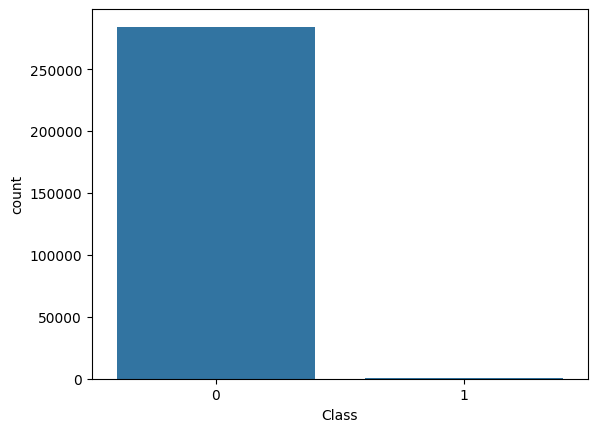

In [ ]:
import seaborn as sns
sns.countplot(data = df, x = "Class")

In [ ]:
print (df[df['Class']==1].count()['Class'])
print (df[df['Class']==0].count()['Class'])

492
284315


<Axes: xlabel='Time', ylabel='Count'>

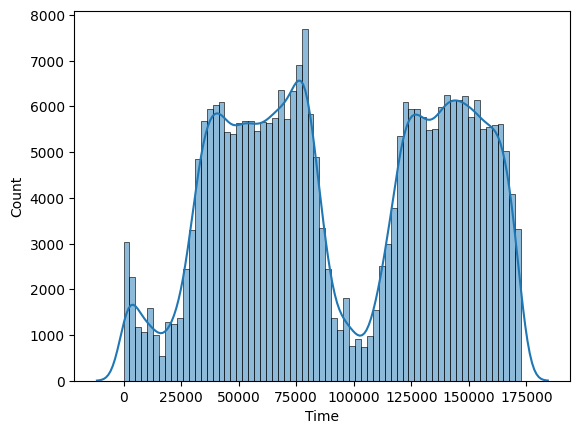

In [ ]:
sns.histplot(df["Time"], kde=True, stat="count", kde_kws=dict(cut=3))

<Axes: xlabel='Amount', ylabel='Count'>

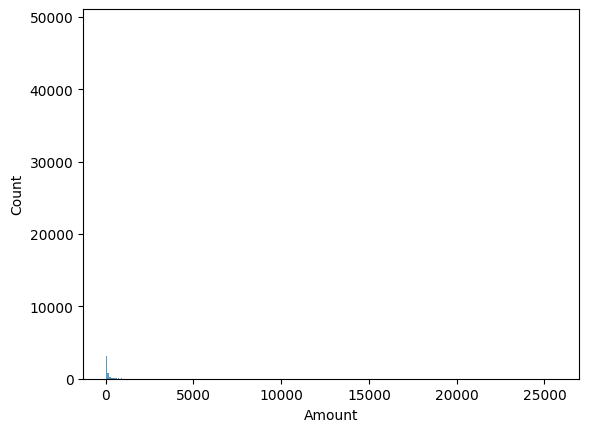

In [ ]:
sns.histplot(df["Amount"], stat="count")

Average fraudulent amount: 122.21132113821133
0.0
2125.87
Fraudulent amount range: $2125.87


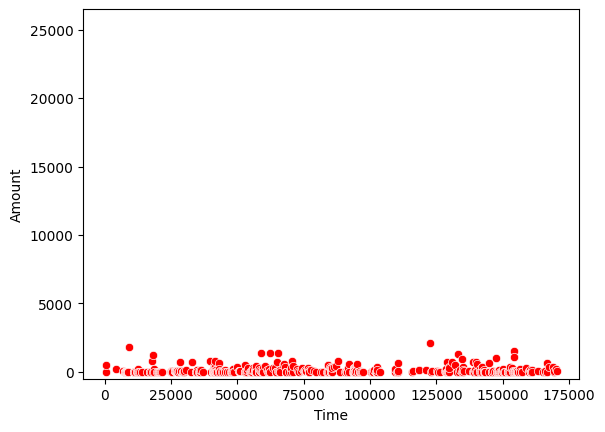

In [ ]:
sns.scatterplot(data = df[df["Class"]==1], x = "Time", y = "Amount", color = "red").set_ylim(-500,26500)

filtered_fraud = []
for index, row in df.iterrows():
    if row['Class'] == 1:
        filtered_fraud.append(row['Amount'])

average_fraudulent_amount = sum(filtered_fraud) / len(filtered_fraud)
print("Average fraudulent amount:", average_fraudulent_amount)

min = filtered_fraud[0]
max = filtered_fraud[0]

for x in filtered_fraud:
  if x < min:
    min = x

print(min)

for x in filtered_fraud:
  if x > max:
    max = x

print(max)

print("Fraudulent amount range: $" + str(max-min))

Average legitimate amount: 88.29102242225574
0.0
25691.16
Legitimate amount range: $25691.16


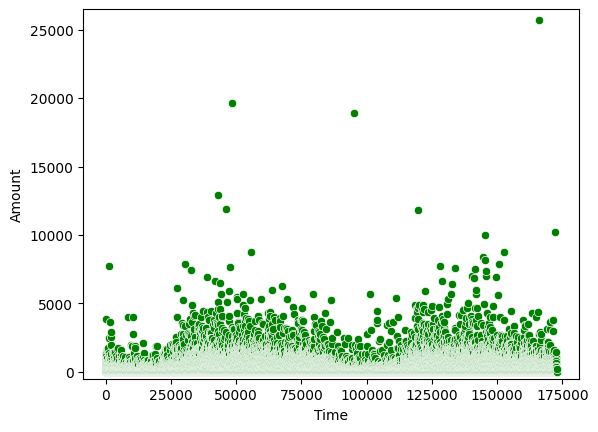

In [ ]:
sns.scatterplot(data = df[df["Class"]==0], x = "Time", y = "Amount", color = "green").set_ylim(-500,26500)

filtered_legit = []
for index, row in df.iterrows():
    if row['Class'] == 0:
        filtered_legit.append(row['Amount'])

average_legit_amount = sum(filtered_legit) / len(filtered_legit)
print("Average legitimate amount:", average_legit_amount)

min = filtered_legit[0]
max = filtered_legit[0]

for x in filtered_legit:
  if x < min:
    min = x

print(min)

for x in filtered_legit:
  if x > max:
    max = x

print(max)

print("Legitimate amount range: $" + str(max-min))

## 3. Decision-tree baseline


Accuracy Score = 0.9990344440153085
F1 Score = 0.7236180904522612
Recall Score = 0.7422680412371134
Precision Score = 0.7058823529411765
AUC = 0.8708702379754547


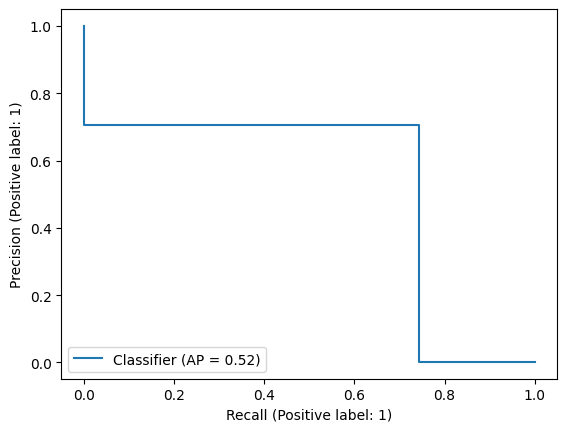

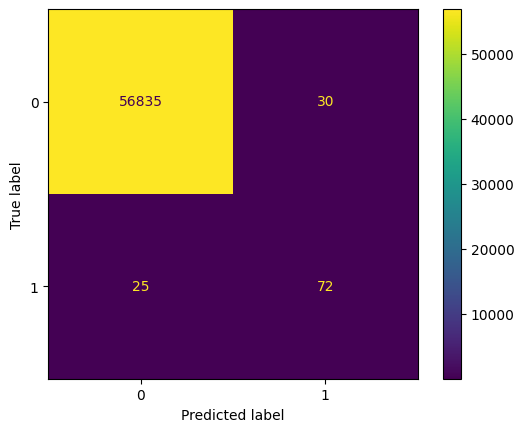

In [ ]:
#assigning each variable data
X = df.drop(labels = "Class", axis = 1)
y = df["Class"]

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn import metrics

#splitting the dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2 )
dt_clf = DecisionTreeClassifier()
dt_clf.fit(X_train, y_train)

y_pred = dt_clf.predict(X_test)
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC = " + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

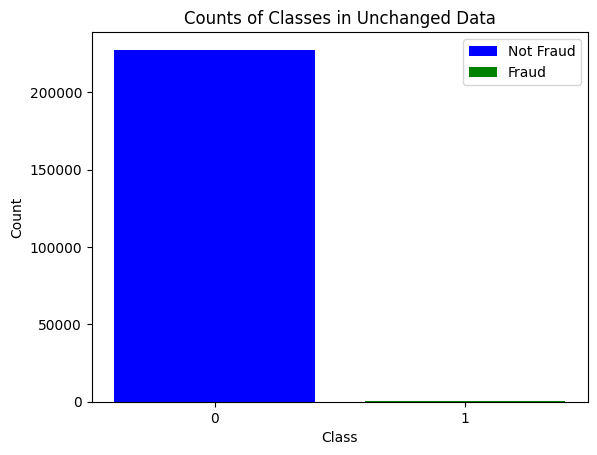

In [ ]:
import matplotlib.pyplot as plt
counts = {'0': y_train.value_counts()[0], '1': y_train.value_counts()[1]}
bars = plt.bar(counts.keys(), counts.values(), color=['blue', 'green'])
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Counts of Classes in Unchanged Data')
plt.legend(bars, ['Not Fraud', 'Fraud'], loc='upper right')
plt.show()

In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    from sklearn import tree
    tree.plot_tree(dt_clf)


## 4. XGBoost baseline


Accuracy Score = 0.9995611109160493
F1 Score = 0.8633879781420764
Recall Score = 0.8144329896907216
Precision Score = 0.9186046511627907
AUC0.9071549455619704


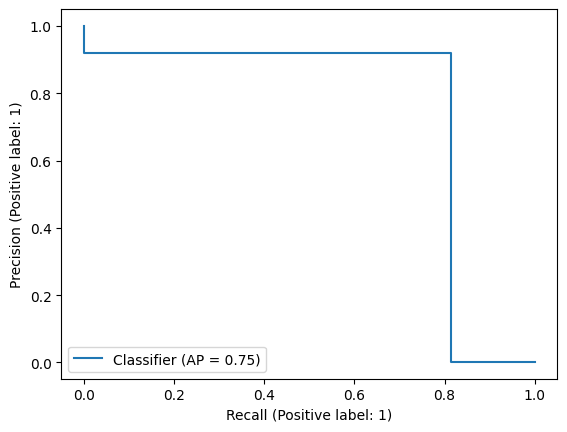

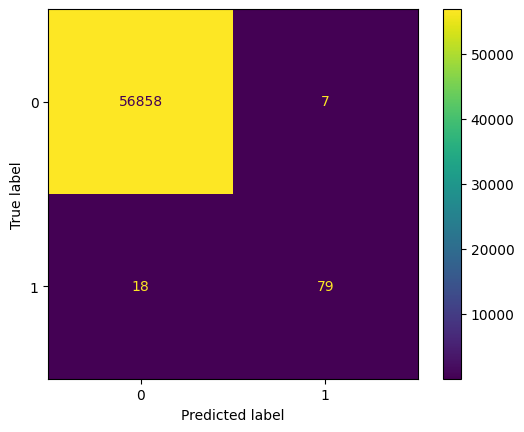

In [ ]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier()
xgb_clf.fit(X_train, y_train)

y_pred= xgb_clf.predict(X_test)
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    from xgboost import plot_tree
    plot_tree(xgb_clf)


## 5. Random oversampling of training data


227450
227450


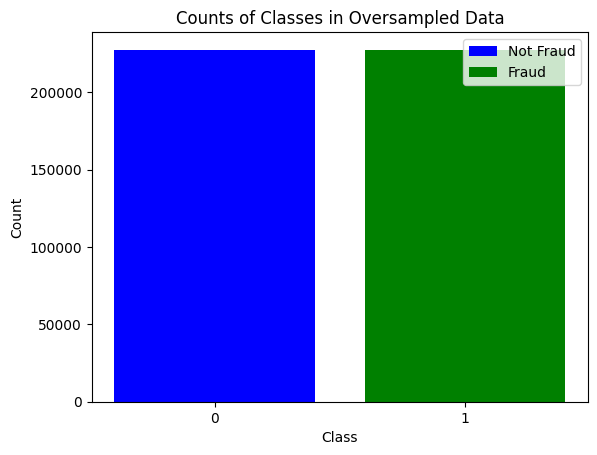

In [ ]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler()

X_over, y_over = ros.fit_resample(X_train, y_train)

print(y_over.value_counts()[0])
print(y_over.value_counts()[1])

import matplotlib.pyplot as plt
counts = {'0': y_over.value_counts()[0], '1': y_over.value_counts()[1]}
bars = plt.bar(counts.keys(), counts.values(), color=['blue', 'green'])
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Counts of Classes in Oversampled Data')
plt.legend(bars, ['Not Fraud', 'Fraud'], loc='upper right')
plt.show()

Accuracy Score = 0.9991397773954567
F1 Score = 0.7379679144385027
Recall Score = 0.711340206185567
Precision Score = 0.7666666666666667
AUC0.8554854552426121


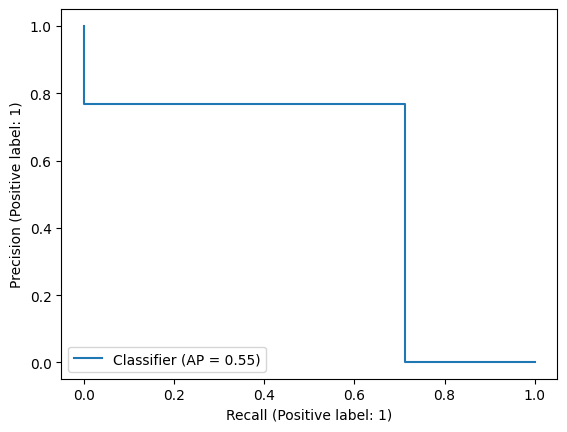

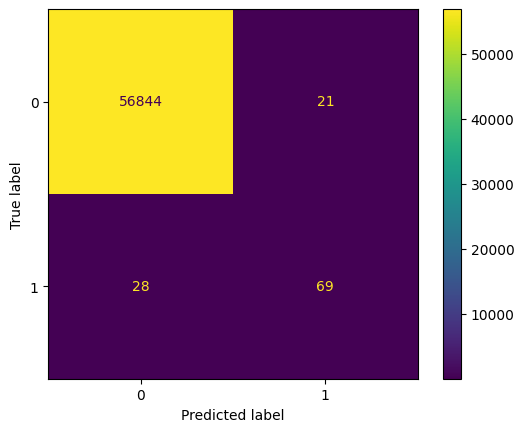

In [ ]:
from imblearn.pipeline import Pipeline, make_pipeline
dt_clf_over = DecisionTreeClassifier()

dt_random_over_pipeline = make_pipeline(ros, dt_clf_over)

dt_random_over_pipeline.fit(X_over, y_over)

y_pred= dt_random_over_pipeline.predict(X_test)

print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [ ]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

AUC0.8554854552426121


In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    tree.plot_tree(dt_clf_over)


Accuracy Score = 0.9995786664794073
F1 Score = 0.8723404255319148
Recall Score = 0.845360824742268
Precision Score = 0.9010989010989011
AUC0.9226012775782034


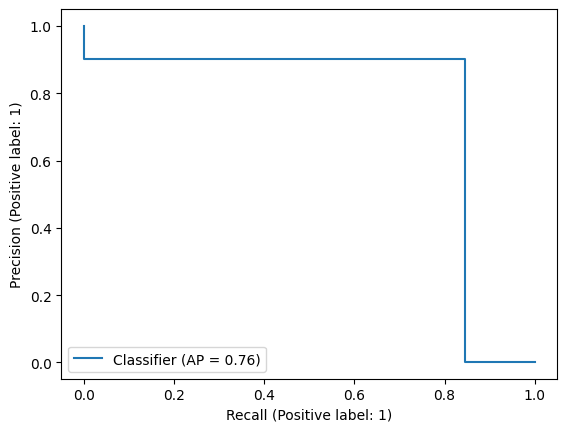

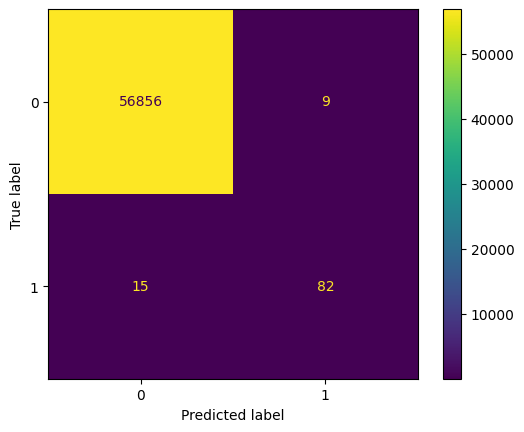

In [ ]:
xgb_clf_over = XGBClassifier()

xgb_random_over_pipeline = make_pipeline(ros, xgb_clf_over)

xgb_random_over_pipeline.fit(X_over, y_over)

y_pred = xgb_random_over_pipeline.predict(X_test)
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    plot_tree(xgb_clf_over)
    fig = plt.gcf()
    fig.set_size_inches(50, 100)
    fig.savefig('tree.png')


## 6. Random undersampling of training data


395
395


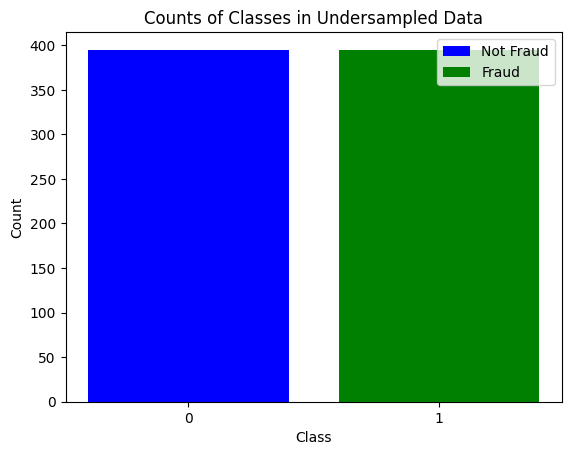

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler()


X_under, y_under = rus.fit_resample(X_train, y_train)

print(y_under.value_counts()[0])
print(y_under.value_counts()[1])

counts = {'0': y_under.value_counts()[0], '1': y_under.value_counts()[1]}
bars = plt.bar(counts.keys(), counts.values(), color=['blue', 'green'])
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Counts of Classes in Undersampled Data')
plt.legend(bars, ['Not Fraud', 'Fraud'], loc='upper right')
plt.show()

Accuracy Score = 0.8877497278887679
F1 Score = 0.028267477203647418
Recall Score = 0.9587628865979382
Precision Score = 0.014345210550670985
AUC0.9231957403182253


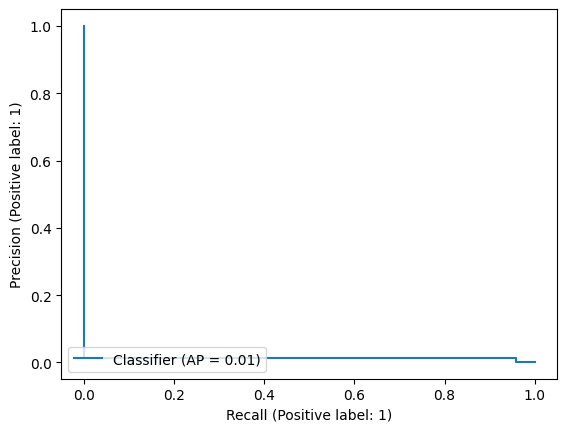

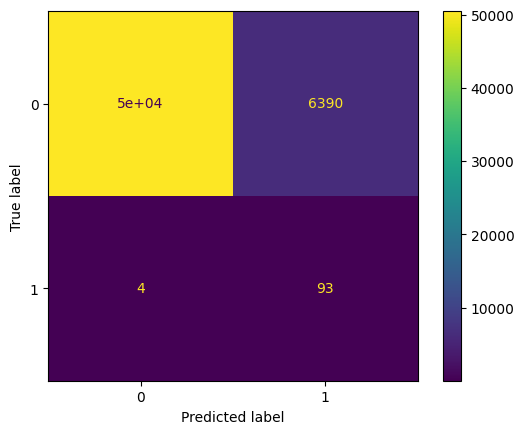

In [ ]:
dt_clf_under = DecisionTreeClassifier()

dt_random_under_pipeline = make_pipeline(rus, dt_clf_under)

dt_random_under_pipeline.fit(X_under, y_under)

y_pred= dt_random_under_pipeline.predict(X_test)
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)



In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    tree.plot_tree(dt_clf_under)


Accuracy Score = 0.953828868368386
F1 Score = 0.06605113636363637
Recall Score = 0.9587628865979382
Precision Score = 0.03420375137918352
AUC0.9562916692727668
[0 0 0 ... 0 0 0]


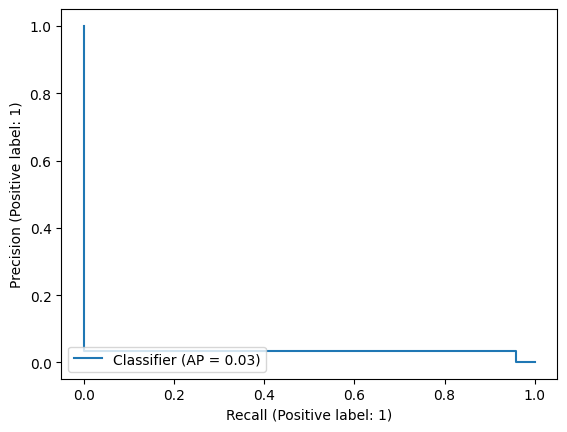

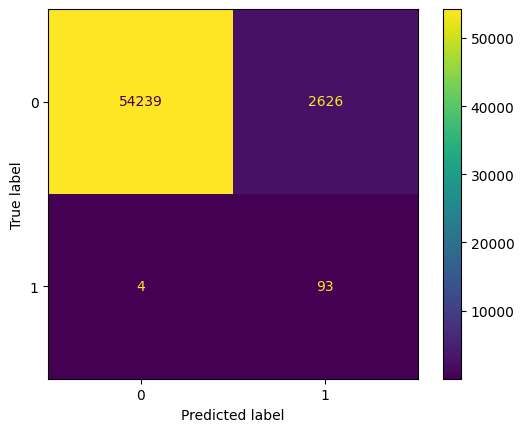

In [ ]:
xgb_clf_under = XGBClassifier()

xgb_random_under_pipeline = make_pipeline(rus, xgb_clf_under)

xgb_random_under_pipeline.fit(X_under, y_under)

y_pred= xgb_random_under_pipeline.predict(X_test)
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))

PrecisionRecallDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
print("AUC" + str(metrics.auc(fpr, tpr)))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

print(y_pred)

In [ ]:
if RUN_TREE_PLOTS:
    import matplotlib.pyplot as plt
    from sklearn import tree
    from xgboost import plot_tree
    plot_tree(xgb_clf_under)
    fig = plt.gcf()
    fig.set_size_inches(50, 100)
    fig.savefig('tree.png')


## Interpretation and reproducibility notes

- Training and test data are split once in this notebook, before resampling. All six classifiers use the same saved run's holdout.
- The split is random, unseeded, and not stratified; it is not a test of future transactions or unseen cardholders.
- The historical pipeline calls resampling on already balanced training arrays. This is redundant at the configured balance ratio; it does not indicate that the test set was resampled.
- The code assigns variables called `min` and `max`, shadowing Python built-ins; these are preserved to avoid rewriting the historical computation.
- New experiments should fix seeds, specify library versions, use prediction scores for ranking metrics, and reserve separate validation data for model/threshold selection.
- The paper's high-recall preference is a stated evaluation priority, not an empirical measurement of operational fraud losses or customer friction.
